In [1]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import function as my
import matplotlib.pyplot as plt
import random
from tqdm import tqdm
import torch.nn as nn

device = tc.device('cuda' if tc.cuda.is_available() else 'cpu')
print(f"Executando no dispositivo: {device}")



Executando no dispositivo: cuda


In [2]:
class FourierField(nn.Module):
    def __init__(self, n_fields=3, M=6, T=2*np.pi):
        super().__init__()
        self.M = M
        self.T = T
        
        # Coeficientes treináveis: a0 (termo DC), a_k (cossenos), b_k (senos)
        # Shape de a0: (3, 1) | Shape de a e b: (3, M)
        self.a0 = nn.Parameter(tc.zeros(n_fields, 1))
        self.a  = nn.Parameter(tc.randn(n_fields, M) * 0.05)
        self.b  = nn.Parameter(tc.randn(n_fields, M) * 0.05)

    def forward(self, t):
        # t shape: (N, 1)
        # k vetor de frequências: [1, 2, ..., M] (shape: 1, M)
        k = tc.arange(1, self.M + 1, device=t.device, dtype=t.dtype).unsqueeze(0)
        
        # Ângulo = (2 * pi * k * t) / T -> shape: (N, M)
        angle = (2.0 * np.pi * t @ k) / self.T
        
        cos_terms = tc.cos(angle) # (N, M)
        sin_terms = tc.sin(angle) # (N, M)
        
        # Multiplicação matricial para somar os harmônicos
        # (N, M) @ (M, 3) -> (N, 3)
        fields = self.a0.T + cos_terms @ self.a.T + sin_terms @ self.b.T
        return fields # Retorna [JX, JY, JZ] com shape (N, 3)
class QubitSystemPINN(nn.Module):
    def __init__(self, state_net, n_fields=3, M=6, T=10.0, N_of_parameter=3):
        super().__init__()
        self.state_net = state_net  # Sua MLP (com ou sem Fourier Features de entrada)
        self.field_net = FourierField(n_fields=n_fields, M=M, T=T)
        self.parametro = nn.Parameter(tc.rand(N_of_parameter)) # gamma1, gamma2, gamma3

    def forward(self, t):
        # 1. Estados preditos pela MLP (N, 9)
        y_states = self.state_net(t) 
        
        # 2. Campos calculados analiticamente pela Série de Fourier (N, 3)
        fields = self.field_net(t)   
        
        # Concatenamos para manter a mesma estrutura original (N, 12)
        return tc.cat([y_states, fields], dim=-1)
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    # Uncomment the following code to use uniform frequency distribution and comment the code below it
    """
    def __init__(self, n_freq, f_max, trainable=True):
        super().__init__()
        self.f_max = f_max
        self.raw_freq = nn.Parameter(tc.randn(n_freq), requires_grad=trainable)

        f0 = tc.linspace(0.05 * f_max, 0.95 * f_max, n_freq)
        raw0 = inv_sigmoid(f0 / f_max)

        self.raw_freq = nn.Parameter(raw0.clone(), requires_grad=trainable)

    def get_freq(self):
        return self.f_max * tc.sigmoid(self.raw_freq)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)   # (batch,1)

        freq = self.get_freq().unsqueeze(0)   # (1,n_freq)
        arg = 2.0 * np.pi * t * freq        # (batch,n_freq)

        return tc.cat([tc.sin(arg), tc.cos(arg)], dim=1)
    """
    def __init__(self, m, sigma=2.0, trainable=False):
        super().__init__()
        B = tc.randn(m, 1) * sigma
        self.B = nn.Parameter(B, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        x = 2 * np.pi * t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
    
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            #self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=True)
            self.ff = FourierFeatures(m=n_freq, sigma=f_max, trainable=True)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [3]:
def Fieldx(t):
    return ( 1.5* np.sin(2.0 * t) - 0.3*np.cos(3* t - 0.5) + 0.4*np.sin(5.0 * t)
        )*np.sin(np.pi*t/tfinal)**2
def Fieldy(t):
    # return np.zeros(len(t))
    return ( 0.5* np.sin(5.0 * t) - 0.8*np.cos(1* t - 0.5) + 1.4*np.sin(3.0 * t)
        )*np.sin(np.pi*t/tfinal)**2

def Fieldz(t):
    # return np.ones(len(t))
    return ( -0.5* np.sin(0.2 * t) - 1.8*np.cos(5* t - 0.5) - .4*np.sin(3.0 * t)
        )*np.sin(np.pi*t/tfinal)**2


/home/castelano/python_env/controle_PINN/.venv/lib/python3.12/site-packages/qutip/solver/options.py:16: FutureWarning: Dedicated options class are no longer needed, options should be passed as dict to solvers.
  warnings.warn(


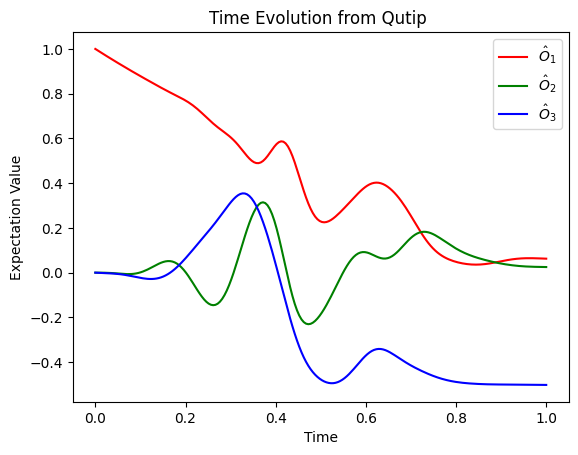

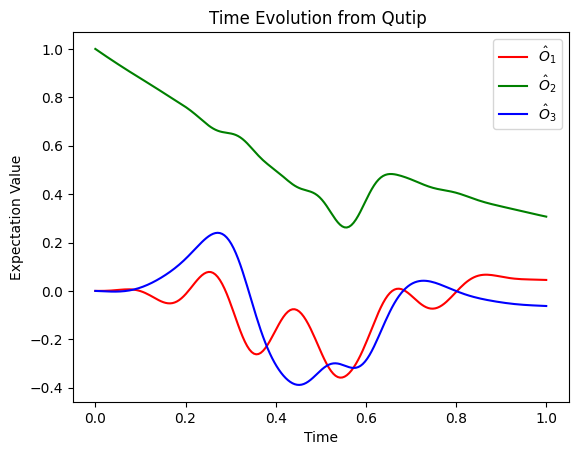

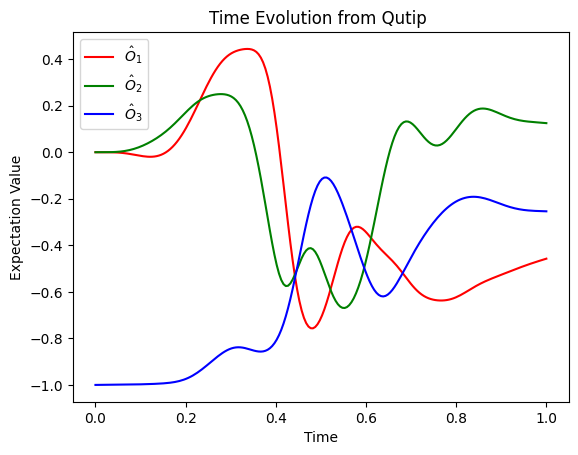

/tmp/ipykernel_12653/2968142281.py:79: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


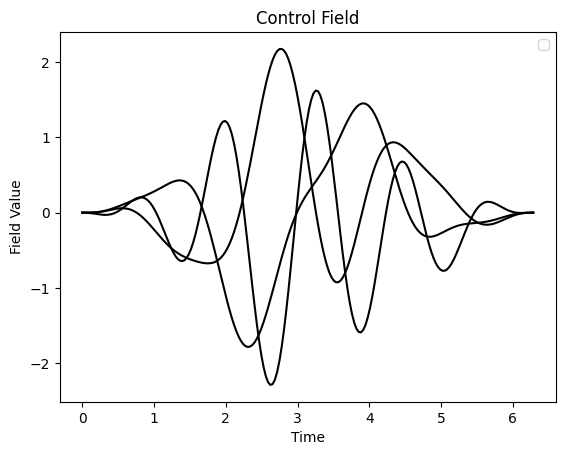

In [4]:

def data_qubit(dissipation,tlist,O_op,fieldx,fieldy,fieldz,psi0,device="cuda"):
    # Operadores de Pauli para cada qubit
    X,Y,Z = qt.sigmax(),qt.sigmay(),qt.sigmaz()
    
    H  = [[0.5*X,fieldx(tlist)],[0.5*Y,fieldy(tlist)],[0.5*Z,fieldz(tlist)]]

    # Hamiltonian Lindbladian
    c_ops = [np.sqrt(dissipation[0])*qt.sigmam(),
             np.sqrt(dissipation[1])*qt.sigmaz(),
             np.sqrt(dissipation[2])*qt.sigmam().dag()]
             
    # Solução da equação de Schrödinger
    options = qt.Options(nsteps = 100000, atol = 1e-14, rtol = 1e-14)
    result  = qt.mesolve(H, psi0, tlist, c_ops=c_ops, e_ops=O_op,options=options)

    expect  = tc.tensor( np.array( result.expect),device = device).transpose(0, 1)
    return expect
O_op =[ qt.sigmax(),qt.sigmay(),qt.sigmaz()]
tfinal      = 2.*np.pi
N           = 200
tlist = np.linspace(0.0, tfinal, N)
SEED=15
# Definindo a seed
np.random.seed(SEED)
tc.manual_seed(SEED) 
random.seed(SEED)

# Js          = np.random.uniform(-1,1,15)
# dissipation = np.random.rand(4)
Js          = [random.uniform(-1,1) for _ in range(3)]
dissipation = [0.1*random.uniform(0,1) for _ in range(3)]
# Estado inicial (cada qubit na superposição de |0> e |1>)
# |+> = (|0> + |1>)/sqrt(2)
theta1  = np.pi/4
phi1    = 0.0 #np.pi/3
ket_plus1 = (np.cos(theta1)*qt.basis(2, 0)+np.sin(theta1)*np.exp(1j*phi1)*qt.basis(2, 1))
psi0 = ket_plus1
valor_esperado_data1  = data_qubit(dissipation,tlist,O_op,Fieldx,Fieldy,Fieldz,psi0,device)
theta1  = np.pi/4
phi1    = np.pi/2
ket_plus1 = (np.cos(theta1)*qt.basis(2, 0)+np.sin(theta1)*np.exp(1j*phi1)*qt.basis(2, 1))
psi0 = ket_plus1
valor_esperado_data2  = data_qubit(dissipation,tlist,O_op,Fieldx,Fieldy,Fieldz,psi0,device)
theta1  = np.pi/2
phi1    = 0*np.pi/4
ket_plus1 = (np.cos(theta1)*qt.basis(2, 0)+np.sin(theta1)*np.exp(1j*phi1)*qt.basis(2, 1))
psi0 = ket_plus1
valor_esperado_data3  = data_qubit(dissipation,tlist,O_op,Fieldx,Fieldy,Fieldz,psi0,device)

colors = ['r', 'g', 'b']
for i in range(len(O_op)):
    plt.plot(tlist/tfinal,valor_esperado_data1[:,i].cpu() ,label=fr"$\hat{{O}}_{{{i+1}}}$", color=colors[i])
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('Time Evolution from Qutip ')
plt.show()
for i in range(len(O_op)):
    plt.plot(tlist/tfinal,valor_esperado_data2[:,i].cpu() ,label=fr"$\hat{{O}}_{{{i+1}}}$", color=colors[i])
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('Time Evolution from Qutip ')
plt.show()
for i in range(len(O_op)):
    plt.plot(tlist/tfinal,valor_esperado_data3[:,i].cpu() ,label=fr"$\hat{{O}}_{{{i+1}}}$", color=colors[i])
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('Time Evolution from Qutip ')
plt.show()


plt.plot(tlist,Fieldx(tlist),'k-')
plt.plot(tlist,Fieldy(tlist),'k-')
plt.plot(tlist,Fieldz(tlist),'k-')
plt.xlabel('Time')
plt.ylabel('Field Value')
plt.legend()
plt.title('Control Field')
plt.show()
        


In [5]:
# 1. Rede MLP tradicional para os 9 estados dos qubits (output_=9)
mlp_states = Rede(
    neuronio=[128, 128],
    input_=1,
    output_=9, # Nedo = 9
    activation=[nn.Tanh()]*2, # Tanh recomendada para estabilidade
    use_fourier=True,
    n_freq=12,
    f_max=2.5
)

# 2. Modelo Unificado (Estados MLP + Campos de Fourier + Gammas)
X_vector = QubitSystemPINN(
    state_net=mlp_states, 
    n_fields=3, 
    M=12, 
    T=tfinal, 
    N_of_parameter=3
).to(device)

time = tc.linspace(
    0,
    tfinal,
    N,
    dtype=tc.float32,
    requires_grad=True
).reshape((-1, 1)).to(device)

opt = tc.optim.Adam(X_vector.parameters(), lr=1e-3)
scheduler = tc.optim.lr_scheduler.StepLR(opt, step_size=5000, gamma=0.5)
LOSS1=[]
LOSS2=[]
LOSS=[]

epocas = 50000

# --- LOOP DE TREINAMENTO ---
for _ in tqdm(range(epocas)):
    opt.zero_grad()
    
    # Avaliação da rede no vetor fixo de tempo
    y = X_vector(time)
    
    # 1. PERDA DOS DADOS (Escalar)
    LOSS_data = 0
    LOSS_data += (y[:, 0:1] - valor_esperado_data1[:, 0:1])**2 
    LOSS_data += (y[:, 1:2] - valor_esperado_data1[:, 1:2])**2 
    LOSS_data += (y[:, 2:3] - valor_esperado_data1[:, 2:3])**2 
    LOSS_data += (y[:, 3:4] - valor_esperado_data2[:, 0:1])**2 
    LOSS_data += (y[:, 4:5] - valor_esperado_data2[:, 1:2])**2 
    LOSS_data += (y[:, 5:6] - valor_esperado_data2[:, 2:3])**2 
    LOSS_data += (y[:, 6:7] - valor_esperado_data3[:, 0:1])**2 
    LOSS_data += (y[:, 7:8] - valor_esperado_data3[:, 1:2])**2 
    LOSS_data += (y[:, 8:9] - valor_esperado_data3[:, 2:3])**2 
    LOSS_data = LOSS_data.mean()
    
    # 2. CÁLCULO DAS DERIVADAS
    dX_dt = []
    for i in range(y.shape[1]):
        dX_dt.append(tc.autograd.grad(
            outputs=y[:, i], 
            inputs=time,
            grad_outputs=tc.ones_like(y[:, i]),
            create_graph=True
        )[0])
    dX_dt = tc.cat(dX_dt, dim=1)
    
    X1, Y1, Z1 = y[:, 0:1], y[:, 1:2], y[:, 2:3]
    X2, Y2, Z2 = y[:, 3:4], y[:, 4:5], y[:, 5:6]
    X3, Y3, Z3 = y[:, 6:7], y[:, 7:8], y[:, 8:9]
    JX, JY, JZ = y[:, 9:10], y[:, 10:11], y[:, 11:12]
    
    gamma1, gamma2, gamma3 = X_vector.parametro

    # 3. PERDA DA EDO
    LOSS_edo  = 0
    LOSS_edo += (dX_dt[:,0:1] - ( + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*X1 + (-1.0*JZ)*Y1 + (1.0*JY)*Z1))**2
    LOSS_edo += (dX_dt[:,1:2] - ( + (1.0*JZ)*X1 + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*Y1 + (-1.0*JX)*Z1))**2
    LOSS_edo += (dX_dt[:,2:3] - ( + (-1.0*gamma1 + 1.0*gamma3) + (-1.0*JY)*X1 + (1.0*JX)*Y1 + (-1.0*gamma1 - 1.0*gamma3)*Z1))**2

    LOSS_edo += (dX_dt[:,3:4] - ( + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*X2 + (-1.0*JZ)*Y2 + (1.0*JY)*Z2))**2
    LOSS_edo += (dX_dt[:,4:5] - ( + (1.0*JZ)*X2 + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*Y2 + (-1.0*JX)*Z2))**2
    LOSS_edo += (dX_dt[:,5:6] - ( + (-1.0*gamma1 + 1.0*gamma3) + (-1.0*JY)*X2 + (1.0*JX)*Y2 + (-1.0*gamma1 - 1.0*gamma3)*Z2))**2

    LOSS_edo += (dX_dt[:,6:7] - ( + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*X3 + (-1.0*JZ)*Y3 + (1.0*JY)*Z3))**2
    LOSS_edo += (dX_dt[:,7:8] - ( + (1.0*JZ)*X3 + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*Y3 + (-1.0*JX)*Z3))**2
    LOSS_edo += (dX_dt[:,8:9] - ( + (-1.0*gamma1 + 1.0*gamma3) + (-1.0*JY)*X3 + (1.0*JX)*Y3 + (-1.0*gamma1 - 1.0*gamma3)*Z3))**2
    
    # --- AQUI ESTAVA O ERRO: Reduzir LOSS_edo para um valor escalar ---
    LOSS_edo = LOSS_edo.mean() 
    
    # 4. CONDIÇÕES DE CONTORNO DOS CAMPOS (Escalar)
    Loss_cc = (JX[0,0] - Fieldx(0.0))**2 + (JX[-1,0] - Fieldx(tfinal))**2
    Loss_cc += (JY[0,0] - Fieldy(0.0))**2 + (JY[-1,0] - Fieldy(tfinal))**2
    Loss_cc += (JZ[0,0] - Fieldz(0.0))**2 + (JZ[-1,0] - Fieldz(tfinal))**2

    # 5. PERDA TOTAL E BACKPROPAGATION (Todos os termos agora são escalares)
    loss_total = LOSS_edo + 1.0 * LOSS_data + Loss_cc
    
    loss_total.backward()
    opt.step()
    LOSS1.append(LOSS_edo.cpu().detach().numpy())
    LOSS2.append(LOSS_data.cpu().detach().numpy())
    LOSS.append(loss_total.cpu().detach().numpy())
    scheduler.step()

100%|██████████| 50000/50000 [06:45<00:00, 123.42it/s]


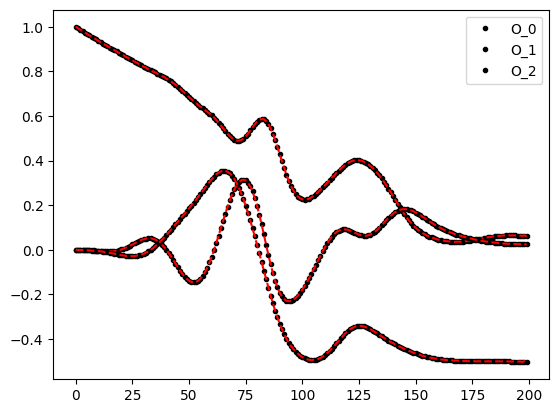

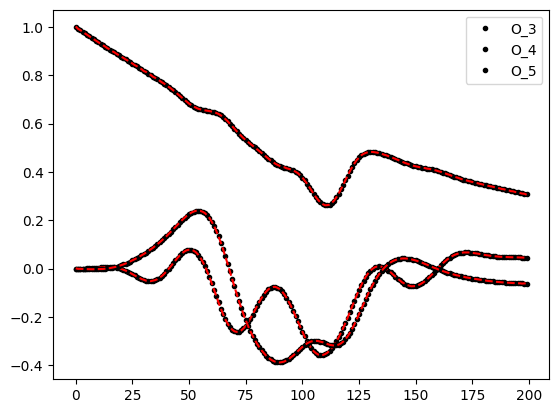

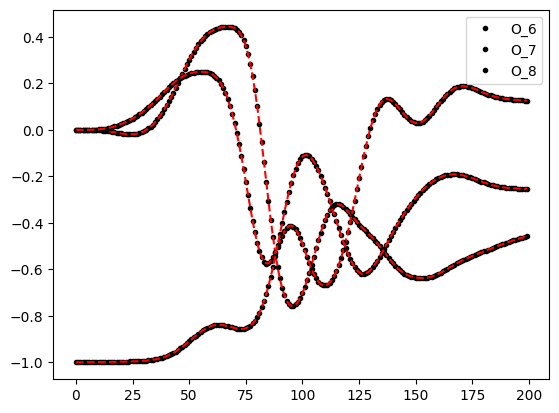

In [6]:
X_vector.eval()
X_  = X_vector(time).cpu().detach().numpy()

for i in range(3):
    plt.plot(valor_esperado_data1[:,i].cpu(),"k." ,label=f"O_{i}")
    plt.plot(X_[:,i],"r--")
plt.legend()
plt.show()

for i in range(3,6):
    plt.plot(valor_esperado_data2[:,i-3].cpu(),"k." ,label=f"O_{i}")
    plt.plot(X_[:,i],"r--")
plt.legend()
plt.show()

for i in range(6,9):
    plt.plot(valor_esperado_data3[:,i-6].cpu(),"k." ,label=f"O_{i}")
    plt.plot(X_[:,i],"r--")
plt.legend()
plt.show()

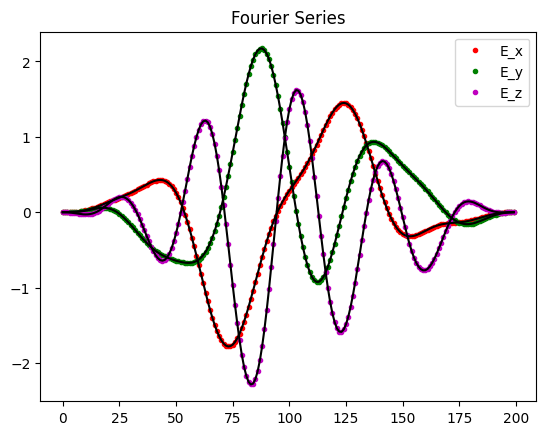

In [7]:
plt.plot(Fieldx(tlist),"r." ,label=f"E_x")
plt.plot(Fieldy(tlist),"g." ,label=f"E_y")
plt.plot(Fieldz(tlist),"m." ,label=f"E_z")
for i in range(9,12):
    plt.plot(X_[:,i],"k")


plt.title("Fourier Series")
plt.legend()
plt.show()